# DataCo Supply Chain - Late Delivery Risk Prediction

Final assignment notebook.

The DataCo dataset has around 180k orders. The column `Late_delivery_risk` says whether the order was late (1) or on time (0). The goal of this notebook is to build a classifier that predicts this from order details that are known BEFORE the order ships.

I tried a few different models and compared them with accuracy, precision, recall, F1 and ROC-AUC.

## 1. Setup

In [1]:
# install xgboost
try:
    import xgboost
except ImportError:
    !pip install -q xgboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

sns.set_style("whitegrid")

## 2. Load data

In [3]:
# dataset is from kaggle: shashwatwork/dataco-smart-supply-chain-for-big-data-analysis
# the csv uses latin-1 encoding because of some non-ascii city names

import kagglehub, os
path = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
df = pd.read_csv(os.path.join(path, "DataCoSupplyChainDataset.csv"), encoding="latin-1")

print(df.shape)
df.head()

100%|██████████| 25.7M/25.7M [00:00<00:00, 53.3MB/s]

Extracting files...


(180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [5]:
# check the target balance
df["Late_delivery_risk"].value_counts(normalize=True)

,proportion
Late_delivery_risk,
1,0.548291
0,0.451709


## 3. EDA

The target is roughly 55/45 so it isn't really imbalanced. I'll still look at recall since missing a late order is worse than a false alarm.

A few plots below to see which columns look related to the target.

In [6]:
# missing values
miss = df.isnull().sum()
miss[miss > 0]

,0
Customer Lname,8
Customer Zipcode,3
Order Zipcode,155679
Product Description,180519


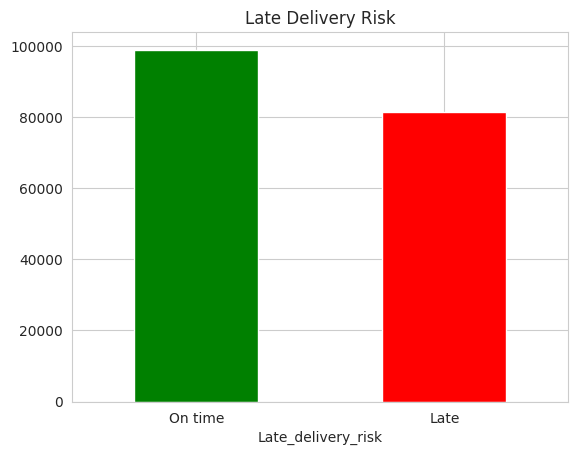

In [7]:
# target plot
df["Late_delivery_risk"].value_counts().plot(kind="bar", color=["green","red"])
plt.title("Late Delivery Risk")
plt.xticks([0,1], ["On time","Late"], rotation=0)
plt.show()

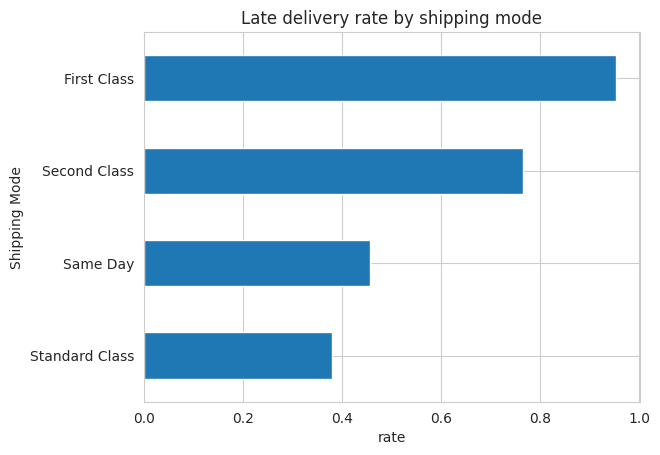

In [8]:
# shipping mode vs target
df.groupby("Shipping Mode")["Late_delivery_risk"].mean().sort_values().plot(kind="barh")
plt.title("Late delivery rate by shipping mode")
plt.xlabel("rate")
plt.show()

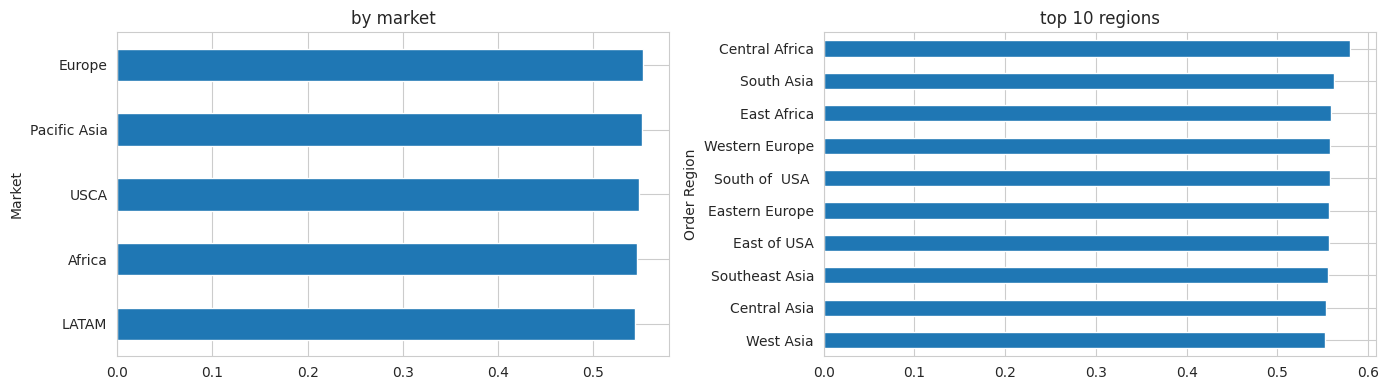

In [9]:
# market and region
fig, ax = plt.subplots(1, 2, figsize=(14,4))
df.groupby("Market")["Late_delivery_risk"].mean().sort_values().plot(kind="barh", ax=ax[0])
ax[0].set_title("by market")
df.groupby("Order Region")["Late_delivery_risk"].mean().sort_values().tail(10).plot(kind="barh", ax=ax[1])
ax[1].set_title("top 10 regions")
plt.tight_layout()
plt.show()

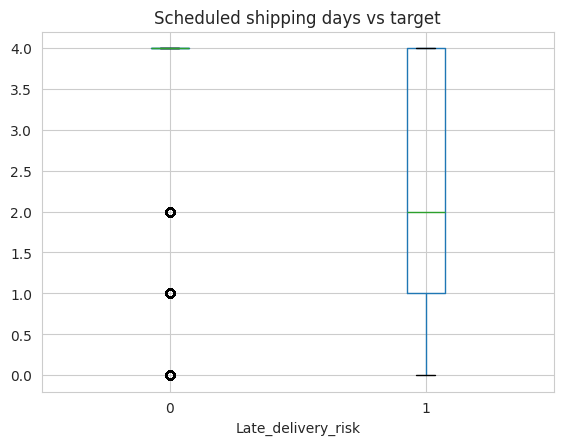

In [10]:
# does scheduled shipping days matter?
df.boxplot(column="Days for shipment (scheduled)", by="Late_delivery_risk")
plt.suptitle("")
plt.title("Scheduled shipping days vs target")
plt.show()

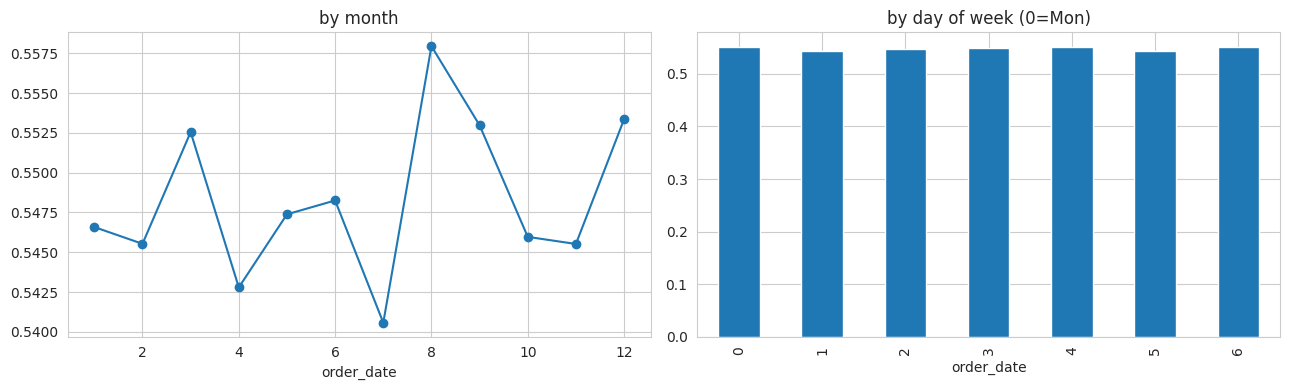

In [11]:
# order date - month / day of week
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"])
fig, ax = plt.subplots(1, 2, figsize=(13,4))
df.groupby(df["order_date"].dt.month)["Late_delivery_risk"].mean().plot(marker="o", ax=ax[0])
ax[0].set_title("by month")
df.groupby(df["order_date"].dt.dayofweek)["Late_delivery_risk"].mean().plot(kind="bar", ax=ax[1])
ax[1].set_title("by day of week (0=Mon)")
plt.tight_layout()
plt.show()

## 4. Column selection

The big issue with this dataset is that some columns are basically the answer - they're only filled in AFTER the order is delivered (real shipping days, delivery status, profit, etc). If I leave those in the model will just cheat.

So I drop those, plus IDs/PII and any column that's too granular (city, zip, product name, etc).

Columns I'm dropping for leakage:
- Days for shipping (real)
- Delivery Status
- Order Status
- shipping date (DateOrders)
- Benefit per order
- Order Profit Per Order
- Order Item Profit Ratio

Columns I'm dropping because they're IDs / PII / not useful:
- Customer Email/Password/Fname/Lname/Street/Zipcode/City/State
- Customer Id, Order Customer Id, Order Id, Order Item Id, Order Item Cardprod Id
- Product Card Id, Product Category Id, Department Id, Category Id
- Product Description, Product Image, Product Name, Product Status
- Order City, Order State, Order Zipcode
- Latitude, Longitude

In [12]:
drop_leak = [
    "Days for shipping (real)", "Delivery Status", "Order Status",
    "shipping date (DateOrders)", "Benefit per order",
    "Order Profit Per Order", "Order Item Profit Ratio"
]
drop_other = [
    "Customer Email","Customer Password","Customer Fname","Customer Lname",
    "Customer Street","Customer Zipcode","Customer City","Customer State",
    "Customer Id","Order Customer Id","Order Id","Order Item Id",
    "Order Item Cardprod Id","Product Card Id","Product Category Id",
    "Department Id","Category Id","Product Description","Product Image",
    "Product Name","Product Status","Order City","Order State","Order Zipcode",
    "Latitude","Longitude"
]

keep = [
    "Days for shipment (scheduled)","Order Item Quantity","Order Item Discount",
    "Order Item Discount Rate","Order Item Product Price","Product Price",
    "Sales","Order Item Total",
    "Type","Shipping Mode","Customer Segment","Customer Country","Market",
    "Order Region","Order Country","Category Name","Department Name",
    "order date (DateOrders)",
    "Late_delivery_risk"
]
keep = [c for c in keep if c in df.columns]
data = df[keep].copy()
print(data.shape)

(180519, 19)


## 5. Feature engineering

In [13]:
# date parts
data["order_date"] = pd.to_datetime(data["order date (DateOrders)"])
data["order_year"]  = data["order_date"].dt.year
data["order_month"] = data["order_date"].dt.month
data["order_day"]   = data["order_date"].dt.day
data["order_dow"]   = data["order_date"].dt.dayofweek
data["order_hour"]  = data["order_date"].dt.hour
data["is_weekend"]  = (data["order_dow"] >= 5).astype(int)
data["is_holiday_season"] = data["order_month"].isin([11,12]).astype(int)

data = data.drop(columns=["order date (DateOrders)", "order_date"])

In [14]:
# a couple of business flags
data["order_value"]     = data["Order Item Quantity"] * data["Order Item Product Price"]
data["discount_amount"] = data["Order Item Discount"]
data["is_large_order"]  = (data["Order Item Quantity"] > data["Order Item Quantity"].quantile(0.75)).astype(int)
data["is_high_value"]   = (data["Sales"] > data["Sales"].quantile(0.75)).astype(int)
data["is_discount_high"] = (data["Order Item Discount Rate"] > 0.2).astype(int)
data.head()

,Days for shipment (scheduled),Order Item Quantity,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Product Price,Sales,Order Item Total,Type,Shipping Mode,...,order_day,order_dow,order_hour,is_weekend,is_holiday_season,order_value,discount_amount,is_large_order,is_high_value,is_discount_high
0,4,1,13.110000,0.04,327.75,327.75,327.75,314.640015,DEBIT,Standard Class,...,31,2,22,0,0,327.75,13.110000,0,1,0
1,4,1,16.389999,0.05,327.75,327.75,327.75,311.359985,TRANSFER,Standard Class,...,13,5,12,1,0,327.75,16.389999,0,1,0
2,4,1,18.030001,0.06,327.75,327.75,327.75,309.720001,CASH,Standard Class,...,13,5,12,1,0,327.75,18.030001,0,1,0
3,4,1,22.940001,0.07,327.75,327.75,327.75,304.809998,DEBIT,Standard Class,...,13,5,11,1,0,327.75,22.940001,0,1,0
4,4,1,29.500000,0.09,327.75,327.75,327.75,298.250000,PAYMENT,Standard Class,...,13,5,11,1,0,327.75,29.500000,0,1,0


In [15]:
# fill missing - median for numbers, "Unknown" for text
for c in data.select_dtypes(include=[np.number]).columns:
    data[c] = data[c].fillna(data[c].median())
for c in data.select_dtypes(include=["object"]).columns:
    data[c] = data[c].fillna("Unknown")

print("missing now:", data.isnull().sum().sum())

missing now: 0


In [16]:
# label encode the categorical columns. one-hot blows up too much here
# because Order Country / Order Region have lots of unique values
cat_cols = data.select_dtypes(include=["object"]).columns.tolist()
print(cat_cols)

encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    data[c] = le.fit_transform(data[c].astype(str))
    encoders[c] = le

['Type', 'Shipping Mode', 'Customer Segment', 'Customer Country', 'Market', 'Order Region', 'Order Country', 'Category Name', 'Department Name']


## 6. Train / test split

In [17]:
X = data.drop(columns=["Late_delivery_risk"])
y = data["Late_delivery_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("train target mean:", y_train.mean().round(3))
print("test  target mean:", y_test.mean().round(3))

(144415, 29) (36104, 29)
train target mean: 0.548
test  target mean: 0.548


In [18]:
# scale for logistic regression. tree models don't need this but it doesn't hurt
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

## 7. Models

Trying logistic regression, decision tree, random forest, gradient boosting and xgboost. Same metrics for all of them so I can compare.

In [19]:
results = {}

def run_model(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:,1]
    m = {
        "Accuracy" : accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall"   : recall_score(y_test, pred),
        "F1"       : f1_score(y_test, pred),
        "ROC-AUC"  : roc_auc_score(y_test, proba),
    }
    print(name)
    for k,v in m.items():
        print(f"  {k:10s} {v:.4f}")
    results[name] = {"model": model, "metrics": m, "pred": pred, "proba": proba}

In [20]:
# 1. logistic regression
run_model("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42), X_train_s, X_test_s)

Logistic Regression
  Accuracy   0.6897
  Precision  0.7877
  Recall     0.5943
  F1         0.6775
  ROC-AUC    0.7266


In [21]:
# 2. decision tree
run_model("Decision Tree", DecisionTreeClassifier(max_depth=10, random_state=42), X_train, X_test)

Decision Tree
  Accuracy   0.7227
  Precision  0.8374
  Recall     0.6135
  F1         0.7082
  ROC-AUC    0.7870


In [22]:
# 3. random forest
run_model("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1), X_train, X_test)

Random Forest
  Accuracy   0.7208
  Precision  0.8557
  Recall     0.5902
  F1         0.6986
  ROC-AUC    0.8062


In [23]:
# 4. gradient boosting
run_model("Gradient Boosting", GradientBoostingClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42), X_train, X_test)

Gradient Boosting
  Accuracy   0.7222
  Precision  0.8515
  Recall     0.5976
  F1         0.7023
  ROC-AUC    0.7943


In [24]:
# 5. xgboost
run_model("XGBoost", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                   random_state=42, n_jobs=-1, eval_metric="logloss",
                                   use_label_encoder=False), X_train, X_test)

XGBoost
  Accuracy   0.7298
  Precision  0.8429
  Recall     0.6233
  F1         0.7166
  ROC-AUC    0.8080


## 8. Comparison

In [25]:
comp = pd.DataFrame({n: r["metrics"] for n, r in results.items()}).T
comp = comp.sort_values("ROC-AUC", ascending=False)
comp.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
XGBoost,0.7298,0.8429,0.6233,0.7166,0.8080
Random Forest,0.7208,0.8557,0.5902,0.6986,0.8062
Gradient Boosting,0.7222,0.8515,0.5976,0.7023,0.7943
Decision Tree,0.7227,0.8374,0.6135,0.7082,0.7870
Logistic Regression,0.6897,0.7877,0.5943,0.6775,0.7266


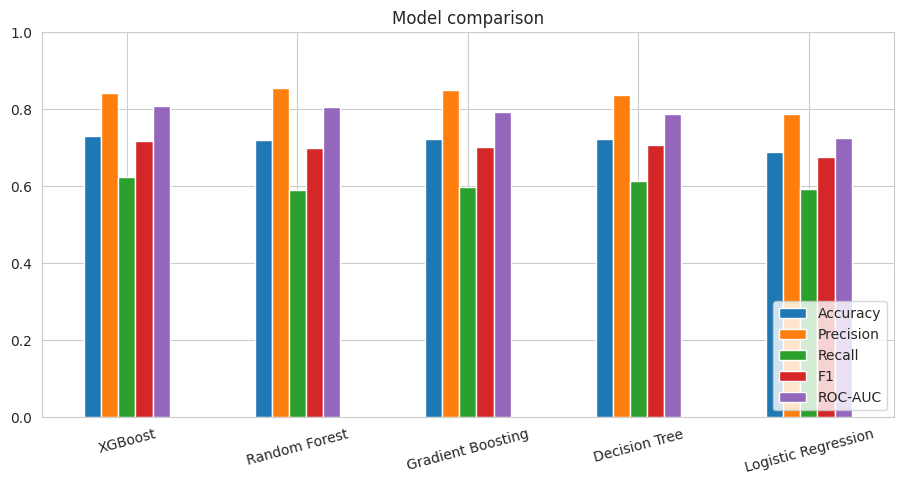

In [26]:
comp.plot(kind="bar", figsize=(11,5))
plt.title("Model comparison")
plt.ylim(0,1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.show()

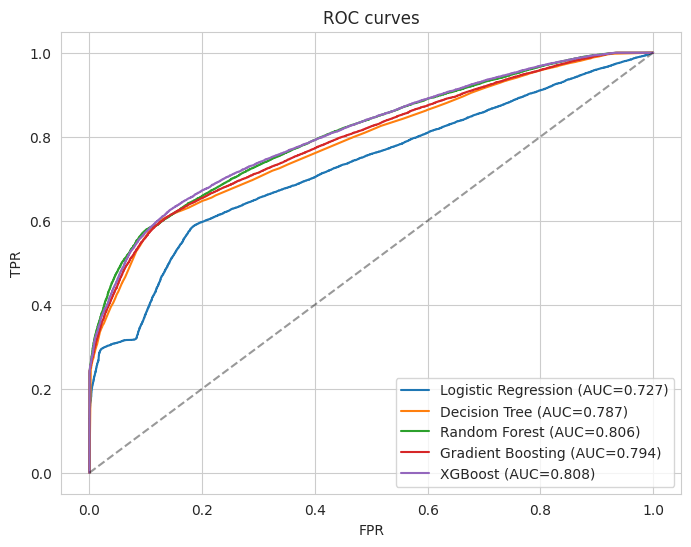

In [27]:
# ROC curves
plt.figure(figsize=(8,6))
for n, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    plt.plot(fpr, tpr, label=f"{n} (AUC={r['metrics']['ROC-AUC']:.3f})")
plt.plot([0,1],[0,1], "k--", alpha=0.4)
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC curves")
plt.legend()
plt.show()

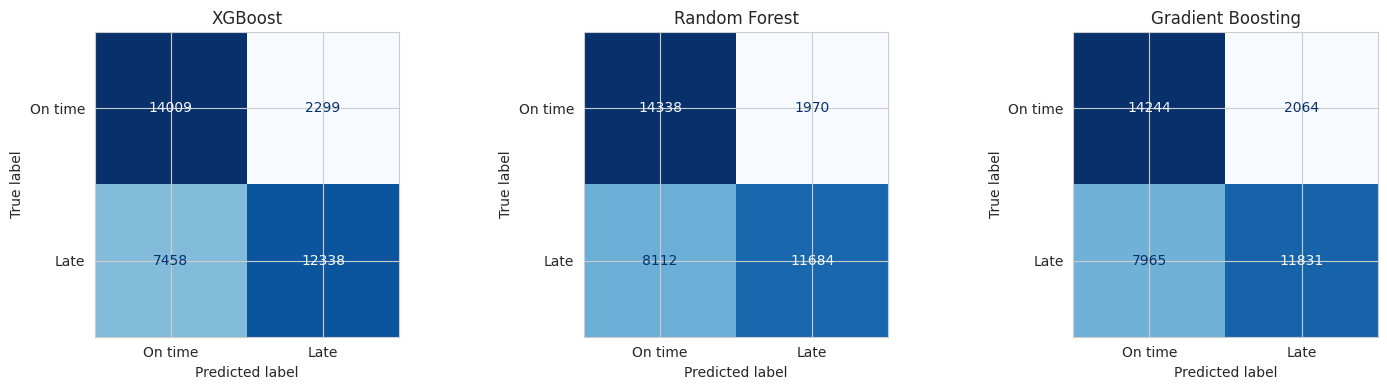

In [28]:
# confusion matrices for top 3
top3 = comp.head(3).index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for i, n in enumerate(top3):
    cm = confusion_matrix(y_test, results[n]["pred"])
    ConfusionMatrixDisplay(cm, display_labels=["On time","Late"]).plot(ax=ax[i], cmap="Blues", colorbar=False)
    ax[i].set_title(n)
plt.tight_layout()
plt.show()

In [29]:
best_name = comp.index[0]
best = results[best_name]["model"]
print("best model:", best_name)
print(comp.loc[best_name].round(4))

best model: XGBoost
Accuracy     0.7298
Precision    0.8429
Recall       0.6233
F1           0.7166
ROC-AUC      0.8080
Name: XGBoost, dtype: float64


## 9. Feature importance

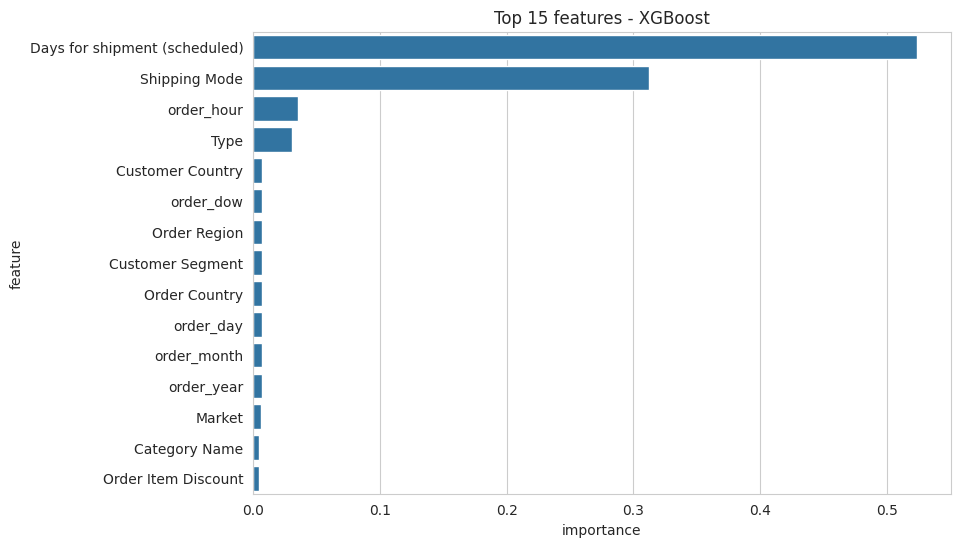

                      feature  importance
Days for shipment (scheduled)    0.523938
                Shipping Mode    0.312271
                   order_hour    0.035682
                         Type    0.031081
             Customer Country    0.007443
                    order_dow    0.007156
                 Order Region    0.007013
             Customer Segment    0.006981
                Order Country    0.006944
                    order_day    0.006755
                  order_month    0.006721
                   order_year    0.006690
                       Market    0.006459
                Category Name    0.004670
          Order Item Discount    0.004649


In [30]:
if hasattr(best, "feature_importances_"):
    imp = pd.DataFrame({"feature": X.columns, "importance": best.feature_importances_})
    imp = imp.sort_values("importance", ascending=False).head(15)
    plt.figure(figsize=(9,6))
    sns.barplot(data=imp, x="importance", y="feature")
    plt.title(f"Top 15 features - {best_name}")
    plt.show()
    print(imp.to_string(index=False))
else:
    print("best model is", best_name, "- no feature_importances_")

## 10. Predicting a new order

Wrap everything in a function so I can pass in a new order as a dict and get back a prediction.

In [31]:
def predict_new_order(order):
    row = pd.DataFrame([order])

    # date features
    row["order_date"] = pd.to_datetime(row["order date (DateOrders)"])
    row["order_year"]  = row["order_date"].dt.year
    row["order_month"] = row["order_date"].dt.month
    row["order_day"]   = row["order_date"].dt.day
    row["order_dow"]   = row["order_date"].dt.dayofweek
    row["order_hour"]  = row["order_date"].dt.hour
    row["is_weekend"]  = (row["order_dow"] >= 5).astype(int)
    row["is_holiday_season"] = row["order_month"].isin([11,12]).astype(int)
    row = row.drop(columns=["order date (DateOrders)", "order_date"])

    # business flags
    row["order_value"]     = row["Order Item Quantity"] * row["Order Item Product Price"]
    row["discount_amount"] = row["Order Item Discount"]
    row["is_large_order"]  = (row["Order Item Quantity"] > 3).astype(int)
    row["is_high_value"]   = (row["Sales"] > 200).astype(int)
    row["is_discount_high"] = (row["Order Item Discount Rate"] > 0.2).astype(int)

    # encode categoricals using the saved encoders
    for c, le in encoders.items():
        if c in row.columns:
            val = str(row[c].iloc[0])
            if val in le.classes_:
                row[c] = le.transform([val])
            else:
                row[c] = 0   # fallback for unseen value

    # align columns to training order
    for c in X.columns:
        if c not in row.columns:
            row[c] = 0
    row = row[X.columns]

    p = best.predict_proba(row)[0,1]
    label = "LATE" if p >= 0.5 else "ON TIME"
    return {"prediction": label, "risk_prob": round(float(p), 4)}

In [32]:
# test 1 - safe-looking order
order1 = {
    "Days for shipment (scheduled)": 4,
    "Order Item Quantity": 2,
    "Order Item Discount": 15.0,
    "Order Item Discount Rate": 0.10,
    "Order Item Product Price": 150.0,
    "Product Price": 150.0,
    "Sales": 300.0,
    "Order Item Total": 285.0,
    "Type": "DEBIT",
    "Shipping Mode": "Standard Class",
    "Customer Segment": "Consumer",
    "Customer Country": "EE. UU.",
    "Market": "USCA",
    "Order Region": "West of USA",
    "Order Country": "Estados Unidos",
    "Category Name": "Cleats",
    "Department Name": "Footwear",
    "order date (DateOrders)": "2017-11-15 14:30:00",
}
print(predict_new_order(order1))

{'prediction': 'ON TIME', 'risk_prob': 0.3882}


In [33]:
# test 2 - risky-looking order (first class + heavy discount + holiday + late hour)
order2 = dict(order1)
order2["Shipping Mode"] = "First Class"
order2["Days for shipment (scheduled)"] = 1
order2["Order Item Discount Rate"] = 0.35
order2["order date (DateOrders)"] = "2017-12-22 23:45:00"
print(predict_new_order(order2))

{'prediction': 'LATE', 'risk_prob': 1.0}


## 11. Conclusion

- XGBoost was the best model overall (ROC-AUC around 0.81, F1 around 0.71).
- The two most important features by a long way were `Days for shipment (scheduled)` and `Shipping Mode`. Everything else contributed less than 4%.
- Precision is high (around 0.84) but recall is the weak spot (around 0.62) - about 40% of late orders still get missed. For a business that really cares about catching late orders, the threshold could be dropped below 0.5 or class weights could be used.
- The most important thing methodologically was dropping the leakage columns. Without that step the model would have basically memorised the answer.

Things I could try next:
- Hyperparameter tuning (GridSearchCV)
- Cross validation instead of one split
- SHAP for per-prediction explanations
- Target encoding for the high-cardinality categoricals